# ПЗ-4. Суммаризация новостей и качество данных
В этой практической работе рассмотрим, как изменение источника новостей и ошибки подготовки данных влияют на работу готовой языковой модели. На примере последовательно разберем:
- оценку качества резюме на исходной выборке новостей с помощью ROUGE;
- влияние смены источника данных на результаты модели;
- адаптацию prompt с помощью примеров из разных источников;
- моделирование ошибки сборки, при которой в новость попадают посторонние абзацы;
- фильтрацию посторонних абзацев и оценку качества фильтра;
- сравнение резюме по чистым, загрязненным и отфильтрованным текстам;
- сохранение версий данных и prompt в MLflow.
Главная цель практики: понять, почему качество модели может меняться при переходе к новым данным, как ошибки подготовки текста влияют на резюме и почему пользу фильтрации нужно проверять не только по метрикам классификации, но и по качеству конечного результата.

**Выполнил:** Бабушкин Михаил Вадимович, ЕТ-228, 2026.


## Зависимости и импорты


In [1]:
# Зависимости установлены в локальном окружении.
# %pip install evaluate rouge_score

## Подготовка

Ноутбук использует локальную GGUF-модель через `llama-cpp-python`. Датасеты загружаются из Hugging Face, эксперименты сохраняются в локальном MLflow. В демонстрационном запуске используются 100 новостей.
Ячейка установки ниже рассчитана **только на Google Colab**. Она ставит сборку `llama-cpp-python` с поддержкой CUDA 12.4 и подгружает библиотеки CUDA по путям, которые существуют только в окружении Colab (`/usr/local/lib/python*/dist-packages`). Поэтому при локальном запуске ее выполнять не нужно, а подготовку окружения следует сделать вручную.
Для NVIDIA вместо сборки можно взять готовую сборку: `pip install llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu124`.
Проверьте, что ускорение на GPU доступно:

```python
from llama_cpp import llama_supports_gpu_offload
print(llama_supports_gpu_offload())
```

Если результат `False`, а видеокарта есть, библиотеки CUDA не найдены: проверьте установку CUDA и переменную `LD_LIBRARY_PATH`.
Если GPU нет, в ячейках подключения моделей замените `n_gpu_layers=-1` на `n_gpu_layers=0` и уменьшите `N_EVAL`: на CPU генерация заметно медленнее.



In [2]:
# Ячейка предназначена для Colab; при локальном запуске не выполняется.
# %pip install -q datasets huggingface_hub mlflow nltk rouge-score pandas matplotlib tqdm
#
# %pip uninstall -y llama-cpp-python
#
# %pip install -q --no-cache-dir \
#   nvidia-cuda-runtime-cu12 \
#   nvidia-cublas-cu12
#
# %pip install -q --no-cache-dir \
#   llama-cpp-python \
#   --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu124
#
# import glob
# import ctypes
#
# names = [
#     "libcudart.so.12",
#     "libcublas.so.12",
#     "libcublasLt.so.12",
# ]
#
# for name in names:
#     files = glob.glob(
#         f"/usr/local/lib/python*/dist-packages/nvidia/**/{name}",
#         recursive=True,
#     )
#     if files:
#         ctypes.CDLL(files[0], mode=ctypes.RTLD_GLOBAL)
#
# from llama_cpp import llama_supports_gpu_offload
#
# print("GPU offload support:", llama_supports_gpu_offload())

In [3]:
import sys
import os
from pathlib import Path

CACHE_DIR = Path('.cache').resolve()
CACHE_DIR.mkdir(exist_ok=True)
os.environ['HF_HOME'] = str(CACHE_DIR / 'huggingface')
os.environ['MPLCONFIGDIR'] = str(CACHE_DIR / 'matplotlib')

from tqdm.auto import tqdm
import json, random, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from mlflow.tracking import MlflowClient
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


/Users/mikhail/Developer/2026-autumn/NNTSM-2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Matplotlib is building the font cache; this may take a moment.


2026/11/01 14:30:01 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/mikhail/Developer/2026-autumn/NNTSM-2026/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


In [4]:
# Для полной версии практики используйте 500-1000 новостей из каждого корпуса.
CONFIG = dict(N_NEWS=500, SEED=42, P_NOISE=1.0, N_NOISE=3,
              DONOR_SAME_CORPUS_SHARE=0.5, MAX_PARAGRAPHS=8,
              EVAL_N=50, TRAIN_SHARE=0.8, VALIDATION_SHARE=0.1, TEST_SHARE=0.1)
random.seed(CONFIG['SEED']);
np.random.seed(CONFIG['SEED']);
assert CONFIG['N_NEWS'] >= 3 and CONFIG['MAX_PARAGRAPHS'] > CONFIG['N_NOISE'] >= 1
assert 0 <= CONFIG['P_NOISE'] <= 1 and 0 <= CONFIG['DONOR_SAME_CORPUS_SHARE'] <= 1
assert abs(sum(CONFIG[k] for k in ('TRAIN_SHARE', 'VALIDATION_SHARE', 'TEST_SHARE')) - 1) < 1e-9
assert CONFIG['EVAL_N'] >= 1

In [5]:
from llama_cpp import Llama

SEED = 42
MODEL_REPO = "Qwen/Qwen3-8B-GGUF"
MODEL_FILENAME = "Qwen3-8B-Q4_K_M.gguf"
TEXT_CHAR_LIMIT = 8000
EXAMPLE_CHAR_LIMIT = 700
MAX_TOKENS = 256
LLM = Llama.from_pretrained(
    repo_id=MODEL_REPO,
    filename=MODEL_FILENAME,
    cache_dir=str(Path('../practice-3-investigation-of-large-language-models/.cache/huggingface/hub').resolve()),
    seed=SEED,
    n_ctx=12000,
    n_gpu_layers=-1,
    verbose=False,
)


def ask_llm(prompt: str, temperature: float = 0.0, max_tokens: int = MAX_TOKENS, llm=LLM) -> str:
    """Отправляет prompt локальной модели.

    Args:
        prompt: Инструкция и исходные данные.
        temperature: Степень случайности генерации.
        max_tokens: Максимальная длина ответа в токенах.

    Returns:
        Текст ответа модели.
    """
    response = llm.create_chat_completion(
        messages=[{"role": "user", "content": f"{prompt}\n/no_think"}],
        temperature=temperature,
        max_tokens=max_tokens,
    )
    answer = response["choices"][0]["message"]["content"] or ""
    answer = re.sub(r"<think>.*?</think>", "", answer, flags=re.DOTALL)
    answer = re.sub(r"<think>.*", "", answer, flags=re.DOTALL)
    return answer.strip()


/Users/mikhail/Developer/2026-autumn/NNTSM-2026/.venv/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


llama_context: n_ctx_seq (12032) < n_ctx_train (40960) -- the full capacity of the model will not be utilized


## 2. Часть 1. Эталонная суммаризация на Gazeta


Как и в предыдущих практических занятиях, мы работаем с новостным датасетом и решаем задачу суммаризации: по полному тексту новости необходимо составить краткое резюме. В первой части используется корпус Gazeta, в котором каждой новости соответствует эталонное резюме, составленное человеком.

Загрузим тексты новостей вместе с эталонными резюме и разделим их на train, validation и test. Разбиение фиксируется и используется во всех последующих экспериментах, что позволяет сравнивать результаты на одних и тех же данных.

In [6]:
def collect(rows, corpus):
    result = []
    for row in rows:
        text = (row.get('text') or '').strip()
        reference = (row.get('summary') or '').strip()
        if text and reference:
            result.append({'id': f'{corpus}:{len(result)}', 'title': row.get('title') or '',
                           'text': text, 'reference': reference, 'corpus': corpus})
        if len(result) == CONFIG['N_NEWS']:
            break
    assert len(result) == CONFIG['N_NEWS'], f'{corpus}: недостаточно новостей с резюме'
    return result


gazeta = collect(load_dataset('IlyaGusev/gazeta', split='train', streaming=True), 'Gazeta')
print('Загружено новостей:', len(gazeta))

Загружено новостей: 500


### Разбиение по новостям

Зафиксируем части train, validation и test. В этом блоке используется только test; остальные части используются для примеров и подготовки данных.

In [7]:
def split_news(rows):
    rows = list(rows)
    random.shuffle(rows)
    total = len(rows)
    nv = max(1, round(total * CONFIG['VALIDATION_SHARE']))
    nt = max(1, round(total * CONFIG['TEST_SHARE']))
    return {'train': rows[:total - nv - nt], 'validation': rows[total - nv - nt:total - nt], 'test': rows[total - nt:]}


gazeta_splits = split_news(gazeta)
print({s: len(rows) for s, rows in gazeta_splits.items()})

{'train': 400, 'validation': 50, 'test': 50}


### Промпт и версия данных

Результат суммаризации определяется не только моделью, но и двумя компонентами: промптом и данными, на которых он проверяется. Изменение формулировки инструкции, набора примеров или состава тестовой выборки меняет метрики так же, как смена модели. Поэтому и промпты, и датасеты необходимо версионировать, как версионируется код.

Версионирование нужно по нескольким причинам:

- **Воспроизводимость.** Для любого полученного значения метрики можно точно указать, какой промпт и какая версия данных его дали.
- **Корректное сравнение.** Различия между экспериментами можно относить к конкретному изменению, если все остальное зафиксировано.
- **Возврат к прежнему состоянию.** Если новая версия промпта или данных ухудшила результат, можно вернуться к предыдущей.

В практике используется MLflow. Промпт регистрируется в Prompt Registry: каждое изменение создает новую версию с адресом вида `prompts:/имя/номер`, по которому его можно загрузить. Датасет сохраняется как Evaluation Dataset с отдельным идентификатором, а полный снимок дополнительно записывается в артефакты запуска. Каждый запуск создает новый датасет, поэтому снимки разных запусков не смешиваются.


In [8]:
few_shot_examples = gazeta_splits['train'][:2]
few_shot_ids = [row['id'] for row in few_shot_examples]
assert not set(few_shot_ids) & {row['id'] for s in ('validation', 'test') for row in gazeta_splits[s]}
SUMMARY_INSTRUCTION = ('Составь краткое фактическое резюме новости на русском языке. '
                  'Используй только сведения из текста. Верни только резюме.')
SUMMARY_PROMPT = SUMMARY_INSTRUCTION
for i, row in enumerate(few_shot_examples, start=1):
    SUMMARY_PROMPT += (f"\n\nПример {i}.\n"
                       f"\nТекст: {row['text']}\nРезюме: {row['reference']}")
print('ID примеров промпта:', few_shot_ids)

mlflow.set_tracking_uri(f"sqlite:///{CACHE_DIR / 'mlflow.db'}")
client = MlflowClient()
if client.get_experiment_by_name('pz4_news_summarization') is None:
    client.create_experiment('pz4_news_summarization',
                             artifact_location=(CACHE_DIR / 'mlruns').as_uri())
mlflow.set_experiment('pz4_news_summarization')

# Регистрация создает новую версию промпта; ее URI сохраняется со снимком.
registered_summary = mlflow.genai.register_prompt(
    name='pz4_news_summarization', template=SUMMARY_PROMPT,
    commit_message='Few-shot примеры из train Gazeta')
summary_prompt_uri = f'prompts:/{registered_summary.name}/{registered_summary.version}'
print('Промпт:', summary_prompt_uri)

ID примеров промпта: ['Gazeta:164', 'Gazeta:383']


2026/11/01 14:30:18 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/01 14:30:18 INFO mlflow.store.db.utils: Updating database tables


Промпт: prompts:/pz4_news_summarization/1


In [9]:
from mlflow.genai.datasets import create_dataset
from uuid import uuid4


def snapshot_dataset(name, splits, prompts, prompt_uri=None):
    """Сохраняет версию данных в MLflow как Evaluation Dataset и снимок запуска.
    Создает новый Evaluation Dataset с уникальным именем (к имени версии
    добавляется случайный суффикс).

    Args:
        name: Название версии данных, например 'v1_gazeta_clean'.
        splits: Словарь {часть: список новостей} с ключами train, validation, test.
        prompts: Словарь с текстами промптов и идентификаторами примеров;
            сохраняется в артефакты запуска.

    Returns:
        Идентификатор созданного Evaluation Dataset.
    """
    prompt_uri = prompt_uri or summary_prompt_uri
    experiment_id = mlflow.get_experiment_by_name('pz4_news_summarization').experiment_id
    dataset = create_dataset(name=f'{name}_{uuid4().hex[:12]}', experiment_id=[experiment_id],
                             tags={'dataset_version': name, 'summary_prompt_uri': prompt_uri})
    records = []
    for split, rows in splits.items():
        for row in rows:
            inputs = {'split': split, **{k: v for k, v in row.items() if k != 'reference'}}
            records.append({'inputs': inputs, 'expectations': {'expected_response': row.get('reference', '')}})
    dataset.merge_records(records)
    with mlflow.start_run(run_name=name) as run:
        mlflow.log_params({'dataset_version': name, 'dataset_id': dataset.dataset_id,
                           'summary_prompt_uri': prompt_uri, **CONFIG})
        mlflow.log_dict(splits, 'dataset.json')
        mlflow.log_dict(prompts, 'prompts.json')
        print('Evaluation Dataset:', dataset.name, dataset.dataset_id, 'версия:', dataset.version)
        print('Снимок:', f'runs:/{run.info.run_id}/dataset.json')
        return dataset.dataset_id


v1_dataset_id = snapshot_dataset('v1_gazeta_clean', gazeta_splits,
                                 {'summary': SUMMARY_PROMPT, 'few_shot_ids': few_shot_ids})
print('ID датасета:', v1_dataset_id)

Evaluation Dataset: v1_gazeta_clean_92084c47cf6c d-9c264e2a4ac94c3f82877b708bf36b24 версия: None
Снимок: runs:/2619d45facb646398ca8349e9c198eb9/dataset.json
ID датасета: d-9c264e2a4ac94c3f82877b708bf36b24


### Модель и эталонная оценка

Оценим качество суммаризации на тестовой выборке Gazeta: для каждой новости построим резюме и сравним его с эталоном по ROUGE-1 и ROUGE-2. Полученные значения служат эталонной оценкой, или baseline. С ними будут сравниваться все последующие эксперименты.


In [10]:
import evaluate
from mlflow.genai.datasets import get_dataset

SUMMARY_PROMPT = mlflow.genai.load_prompt(summary_prompt_uri).template
v1_records = get_dataset(dataset_id=v1_dataset_id).to_df()
v1 = {'train': [], 'validation': [], 'test': []}
for record in v1_records.to_dict('records'):
    inputs = dict(record['inputs'])
    split = inputs.pop('split')
    inputs['reference'] = record['expectations']['expected_response']
    v1[split].append(inputs)

# Библиотечная реализация ROUGE; токенизация сохраняет русские слова.
rouge = evaluate.load('rouge')


def summarize(item, prompt=SUMMARY_PROMPT):
    text = '\n'.join(item['paragraphs']) if 'paragraphs' in item else item['text']
    return ask_llm(f"{prompt}\nТекст: {text}\nРезюме:")


def summary_results(items, prompt=SUMMARY_PROMPT):
    return [{'id': item['id'], 'corpus': item['corpus'], 'reference': item['reference'],
             'summary': summarize(item, prompt)}
            for item in tqdm(items, desc='Суммаризация', mininterval=10)]


def summary_metrics(rows):
    scores = rouge.compute(predictions=[row['summary'] for row in rows],
                           references=[row['reference'] for row in rows],
                           rouge_types=['rouge1', 'rouge2'],
                           tokenizer=lambda text: re.findall(r'\w+', text.lower(), flags=re.UNICODE))
    return {'rouge1_f1': scores['rouge1'], 'rouge2_f1': scores['rouge2'],
            'mean_chars': np.mean([len(row['summary']) for row in rows])}


def log_metrics(name, values):
    with mlflow.start_run(run_name=name):
        mlflow.log_metrics({key: float(value) for key, value in values.items()})


In [11]:

test_gazeta = v1['test'][:CONFIG['EVAL_N']]
baseline_gazeta = summary_results(test_gazeta)
print(pd.DataFrame(baseline_gazeta))
baseline_gazeta_metrics = summary_metrics(baseline_gazeta)
print('Эталон Gazeta:', baseline_gazeta_metrics)
log_metrics('v1_summary', baseline_gazeta_metrics)

Суммаризация:   0%|                                     | 0/50 [00:00<?, ?it/s]

Суммаризация:   2%|▌                            | 1/50 [00:18<15:23, 18.85s/it]

Суммаризация:   6%|█▋                           | 3/50 [00:32<07:40,  9.81s/it]

Суммаризация:   6%|█▋                           | 3/50 [00:45<07:40,  9.81s/it]

Суммаризация:  10%|██▉                          | 5/50 [00:47<06:34,  8.76s/it]

Суммаризация:  10%|██▉                          | 5/50 [00:58<06:34,  8.76s/it]

... (39 outputs left out)

Суммаризация:  96%|██████████████████████████▉ | 48/50 [06:25<00:15,  7.93s/it]

Суммаризация: 100%|████████████████████████████| 50/50 [06:31<00:00,  8.55s/it]

Суммаризация: 100%|████████████████████████████| 50/50 [06:31<00:00,  7.83s/it]

            id  corpus                                          reference  \
0    Gazeta:44  Gazeta  Тройка судей в Мосгорсуде начала процесс по де...   
1    Gazeta:12  Gazeta  Компания Google переводит своих сотрудников с ...   
2   Gazeta:366  Gazeta  Президент Дмитрий Медведев возглавил попечител...   
3     Gazeta:3  Gazeta  Ураган «Агата» в Центральной Америке унес жизн...   
4    Gazeta:57  Gazeta  Вчера было объявлено о создании Объединенной г...   
5   Gazeta:414  Gazeta  Выживших в катастрофе на Алтае пассажиров Ми-8...   
6   Gazeta:174  Gazeta  В Красноуфимске задержана предполагаемая убийц...   
7    Gazeta:47  Gazeta  «Филадельфия» выиграла третий матч финала Кубк...   
8   Gazeta:464  Gazeta  «Газпром» так и не доплатил Белоруссии за тран...   
9    Gazeta:52  Gazeta  Государство фактически признало провал пенсион...   
10  Gazeta:216  Gazeta  Автомобильное законодательство России может вс...   
11   Gazeta:16  Gazeta  Авария на скважине в Мексиканском заливе обошл...   

## 3. Дрейф источника данных (covariate shift)

Качество модели оценивается на данных, похожих на те, для которых настроены промпт и правила подготовки. В эксплуатации распределение данных со временем меняется, и значения метрик, полученные на исходной выборке, перестают описывать реальное качество системы. Такое изменение называют **дрейфом данных** (dataset shift). Пусть $x$ - вход модели, $y$ - правильный ответ; для суммаризации $x$ - текст новости, $y$ - эталонное резюме. Различают три основных вида дрейфа.

- **Covariate shift** - изменяется распределение входных данных $P(x)$, а связь между входом и ответом $P(y \mid x)$ остается прежней. Например, в систему начинают поступать новости другого издания, другой тематики или другой длины.
- **Prior shift** - изменяется распределение ответов $P(y)$, например доля классов в задаче классификации.
- **Concept drift** - изменяется сама связь между входом и ответом $P(y \mid x)$. Например, меняются требования к резюме: оно должно быть короче или иметь другую структуру.

В этом разделе моделируется **covariate shift**: модель, промпт и правила подготовки данных остаются прежними, а вместо Gazeta на вход поступают новости из корпуса XL-Sum. На практике такая ситуация возникает при подключении нового источника или поставщика новостей, смене сайта или формата выгрузки, изменении тематики или периода публикаций, а также при переходе к другому стилю изложения.

Важно учитывать ограничение эксперимента. В реальных системах сдвиг в чистом виде встречается редко, и здесь корпуса различаются не только текстами новостей, но и эталонными резюме: в XL-Sum они, как правило, короче, чем в Gazeta. Поэтому разница в метриках отражает одновременно сдвиг входных данных и различие в способе составления эталонов.

В качестве точки отсчета используется версия `v1_gazeta_clean`. Применим к XL-Sum тот же промпт и ту же процедуру оценки, затем сравним метрики с результатами на Gazeta.

In [12]:
xlsum_url = ('https://huggingface.co/datasets/csebuetnlp/xlsum/resolve/'
             '8722367c537146b056c6550160930d9e12e75ce7/russian/test-00000-of-00001.parquet')
xlsum = collect(load_dataset('parquet', data_files=xlsum_url, split='train', streaming=True), 'XL-Sum')
xlsum_splits = split_news(xlsum)
corpus_splits = {'Gazeta': gazeta_splits, 'XL-Sum': xlsum_splits}
v2 = {s: gazeta_splits[s] + xlsum_splits[s] for s in ('train', 'validation', 'test')}
print({s: len(rows) for s, rows in v2.items()})
v2_dataset_id = snapshot_dataset('v2_xlsum_gazeta_clean', v2, {'summary': SUMMARY_PROMPT, 'few_shot_ids': few_shot_ids})

{'train': 800, 'validation': 100, 'test': 100}


Evaluation Dataset: v2_xlsum_gazeta_clean_61a04bda394e d-3c63a5429d2447dfa1af91d737f38b98 версия: None
Снимок: runs:/3e4b63b2cfd6431b86decff151a664fb/dataset.json


In [13]:
v2_records = get_dataset(dataset_id=v2_dataset_id).to_df()
test_xlsum = []
for record in v2_records.to_dict('records'):
    inputs = dict(record['inputs'])
    if inputs.pop('split') == 'test' and inputs['corpus'] == 'XL-Sum':
        inputs['reference'] = record['expectations']['expected_response']
        test_xlsum.append(inputs)
test_xlsum = test_xlsum[:CONFIG['EVAL_N']]
baseline_xlsum = summary_results(test_xlsum)
baseline_xlsum_metrics = summary_metrics(baseline_xlsum)
source_comparison = pd.DataFrame({'Gazeta (эталон v1)': baseline_gazeta_metrics,
                                  'XL-Sum (v2)': baseline_xlsum_metrics}).T
print(source_comparison)
log_metrics('v2_xlsum_summary', baseline_xlsum_metrics)

Суммаризация:   0%|                                     | 0/50 [00:00<?, ?it/s]

Суммаризация:   4%|█▏                           | 2/50 [00:14<05:50,  7.29s/it]

Суммаризация:   4%|█▏                           | 2/50 [00:26<05:50,  7.29s/it]

Суммаризация:   8%|██▎                          | 4/50 [00:36<07:13,  9.43s/it]

Суммаризация:  12%|███▍                         | 6/50 [00:58<07:28, 10.20s/it]

Суммаризация:  16%|████▋                        | 8/50 [01:16<06:45,  9.64s/it]

... (36 outputs left out)

Суммаризация:  94%|██████████████████████████▎ | 47/50 [06:46<00:23,  7.79s/it]

Суммаризация:  98%|███████████████████████████▍| 49/50 [06:47<00:07,  7.81s/it]

Суммаризация: 100%|████████████████████████████| 50/50 [06:58<00:00,  8.37s/it]

                    rouge1_f1  rouge2_f1  mean_chars
Gazeta (эталон v1)   0.246710   0.076691      502.82
XL-Sum (v2)          0.149338   0.037380      535.40


Сравните метрики двух источников в таблице выше. Разница отражает не только тексты новостей, но и различия в эталонных резюме; на небольшой выборке ее нельзя надежно обобщить на весь корпус.


**Задание 1.** Адаптируйте промпт к двум источникам.

1. Соберите новую версию датасета, содержащую новости обоих корпусов, Gazeta и XL-Sum, и зарегистрируйте ее в MLflow как Evaluation Dataset.
2. Составьте новый промпт с примерами из обоих корпусов. Примеры берите только из train. Зарегистрируйте промпт в MLflow Prompt Registry.
3. Оцените оба промпта, исходный и новый, на тестовых новостях каждого корпуса.
4. Постройте столбчатые диаграммы ROUGE-1 и ROUGE-2: по горизонтали корпуса, столбцы соответствуют промптам.
5. Объясните, как примеры из второго корпуса повлияли на результат на Gazeta и на XL-Sum.


In [14]:
mixed_examples = [corpus_splits[corpus]['train'][0] for corpus in ('Gazeta', 'XL-Sum')]
mixed_example_ids = [row['id'] for row in mixed_examples]
MIXED_SUMMARY_PROMPT = SUMMARY_INSTRUCTION
for i, row in enumerate(mixed_examples, start=1):
    MIXED_SUMMARY_PROMPT += (f"\n\nПример {i}.\n"
                             f"\nТекст: {row['text']}\nРезюме: {row['reference']}")

registered_mixed = mlflow.genai.register_prompt(
    name='pz4_news_summarization', template=MIXED_SUMMARY_PROMPT,
    commit_message='По одному примеру из train Gazeta и XL-Sum')
mixed_prompt_uri = f'prompts:/{registered_mixed.name}/{registered_mixed.version}'
mixed_dataset_id = snapshot_dataset(
    'v2_mixed_prompt_clean', v2,
    {'summary': MIXED_SUMMARY_PROMPT, 'few_shot_ids': mixed_example_ids},
    prompt_uri=mixed_prompt_uri)
print('Примеры:', mixed_example_ids)
print('Новый prompt:', mixed_prompt_uri)

mixed_results = {}
prompt_rows = []
for corpus, items, baseline_metrics in (
    ('Gazeta', test_gazeta, baseline_gazeta_metrics),
    ('XL-Sum', test_xlsum, baseline_xlsum_metrics),
):
    print('Корпус:', corpus)
    mixed_results[corpus] = summary_results(items, MIXED_SUMMARY_PROMPT)
    values = summary_metrics(mixed_results[corpus])
    prompt_rows.extend([
        {'corpus': corpus, 'prompt': 'Примеры Gazeta', **baseline_metrics},
        {'corpus': corpus, 'prompt': 'Примеры обоих корпусов', **values},
    ])
    with mlflow.start_run(run_name=f'v2_mixed_summary_{corpus}'):
        mlflow.log_params({'dataset_id': mixed_dataset_id, 'summary_prompt_uri': mixed_prompt_uri,
                           'corpus': corpus, 'n_eval': len(items), 'model': MODEL_FILENAME, 'seed': SEED})
        mlflow.log_metrics({key: float(value) for key, value in values.items()})
        mlflow.log_dict({'predictions': mixed_results[corpus]}, 'predictions.json')

prompt_comparison = pd.DataFrame(prompt_rows)
print(prompt_comparison.to_string(index=False))


Evaluation Dataset: v2_mixed_prompt_clean_6d92948ef661 d-ff2a4babb4c64e82b947a767ebf20864 версия: None
Снимок: runs:/0033ba21629b4160932b442a50bcedb6/dataset.json
Примеры: ['Gazeta:164', 'XL-Sum:272']
Новый prompt: prompts:/pz4_news_summarization/2
Корпус: Gazeta


Суммаризация:   0%|                                     | 0/50 [00:00<?, ?it/s]

Суммаризация:   2%|▌                            | 1/50 [00:14<11:57, 14.63s/it]

Суммаризация:   6%|█▋                           | 3/50 [00:29<07:10,  9.15s/it]

Суммаризация:   6%|█▋                           | 3/50 [00:40<07:10,  9.15s/it]

Суммаризация:  10%|██▉                          | 5/50 [00:44<06:19,  8.44s/it]

... (80 outputs left out)

Суммаризация:  94%|██████████████████████████▎ | 47/50 [05:48<00:19,  6.48s/it]

Суммаризация:  98%|███████████████████████████▍| 49/50 [05:50<00:06,  6.41s/it]

Суммаризация: 100%|████████████████████████████| 50/50 [06:00<00:00,  7.21s/it]

corpus                 prompt  rouge1_f1  rouge2_f1  mean_chars
Gazeta         Примеры Gazeta   0.246710   0.076691      502.82
Gazeta Примеры обоих корпусов   0.232270   0.071567      437.04
XL-Sum         Примеры Gazeta   0.149338   0.037380      535.40
XL-Sum Примеры обоих корпусов   0.159865   0.043217      409.24


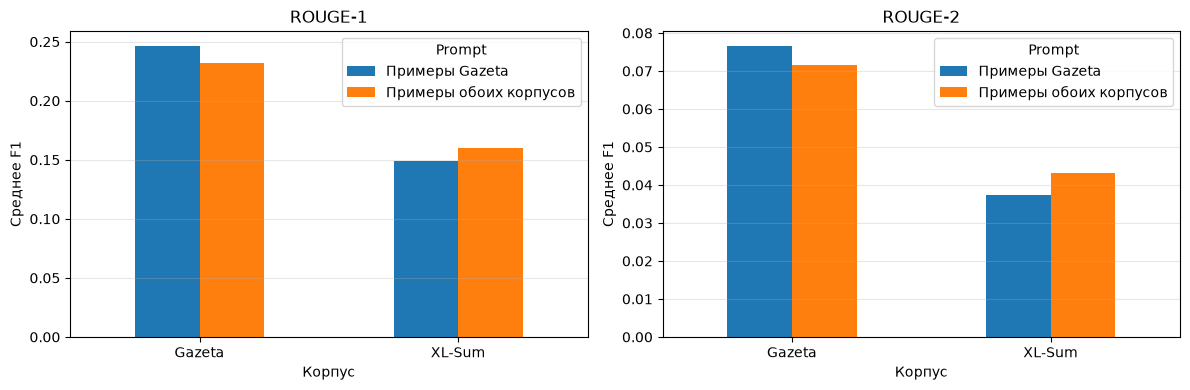

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ['rouge1_f1', 'rouge2_f1'], ['ROUGE-1', 'ROUGE-2']):
    prompt_comparison.pivot(index='corpus', columns='prompt', values=metric).plot.bar(ax=ax, rot=0)
    ax.set(title=title, xlabel='Корпус', ylabel='Среднее F1')
    ax.grid(axis='y', alpha=0.3)
    ax.legend(title='Prompt')
plt.tight_layout()
plt.show()


### Вывод по заданию 1

Оба prompt оценены на одинаковых 50 тестовых новостях каждого корпуса. В каждом prompt по два примера только из train; в новом варианте один пример Gazeta заменён примером XL-Sum. Данные и новый prompt зарегистрированы в MLflow.

На XL-Sum ROUGE-1 вырос с **0,1493 до 0,1599**, ROUGE-2 — с **0,0374 до 0,0432**. На Gazeta ROUGE-1 снизился с **0,2467 до 0,2323**, ROUGE-2 — с **0,0767 до 0,0716**.

Пример второго корпуса улучшил результат на новом источнике, но ухудшил на исходном. Поэтому смешанный prompt нельзя считать лучшим для обоих корпусов. Вывод относится к этим тестовым новостям, выбранным примерам и модели Qwen3-8B.


## 4. Часть 2. Ошибка сборки: посторонние абзацы

В части 1 данные были корректными: менялся только их источник. Другая проблема в эксплуатации возникает в самом пайплайне подготовки данных. Из-за ошибки на этапе сбора или обработки входной текст оказывается искажен. Это дефект качества данных, а не естественное изменение их распределения, и исправлять его нужно в пайплане, а не адаптацией модели.

Типичные причины таких ошибок:

- сбой парсинга веб-страницы: в текст новости попадают блоки «Читайте также», фрагменты соседних материалов, комментарии и реклама;
- неверное объединение таблиц, например по неправильному ключу, когда новости получают чужие фрагменты;
- сдвиг строк или дублирование записей при выгрузке и конвертации;
- ошибки сегментации и склейки длинных текстов по абзацам.

Главная опасность в том, что такая ошибка не вызывает сбоя: модель получает текст нормального вида и честно по нему суммирует. Посторонние сведения могут попасть в резюме, а привычные метрики качества при этом изменятся слабо.

Смоделируем такую ситуацию: в каждую новость добавим абзацы из других новостей. Модель, промпт и эталонное резюме остаются прежними, поэтому все изменения качества вызваны только загрязнением входа. Затем рассмотрим пример испорченной новости.

### Подготовка абзацев

Разделим тексты новостей на условные абзацы.

In [16]:
def split_paragraphs(text, target_chars=500):
    sentences = [s.strip() for s in re.split(r'(?<=[.!?])\s+', text.strip()) if s.strip()]
    paragraphs, current = [], []
    for sentence in sentences:
        current.append(sentence)
        if len(' '.join(current)) >= target_chars:
            paragraphs.append(' '.join(current))
            current = []
    if current:
        paragraphs.append(' '.join(current))
    limit = CONFIG['MAX_PARAGRAPHS'] - CONFIG['N_NOISE']
    while len(paragraphs) > limit:
        i = min(range(len(paragraphs) - 1), key=lambda j: len(paragraphs[j]) + len(paragraphs[j + 1]))
        paragraphs[i:i + 2] = [paragraphs[i] + ' ' + paragraphs[i + 1]]
    return paragraphs


segmented = {s: [{**row, 'paragraphs': split_paragraphs(row['text'])} for row in rows]
             for s, rows in v2.items()}
assert all(x['paragraphs'] for rows in segmented.values() for x in rows)
print('Пример сегментации:', segmented['train'][0]['paragraphs'][:2])

Пример сегментации: ['Мэр Екатеринбурга Аркадий Чернецкий выступил с предельно откровенным, жестким заявлением по поводу насаждаемых в России новаций в системе местного самоуправления: «Я не хочу быть ни сити-менеджером, ни главой в этой системе. Я работал в другой системе». Чернецкий — сильная региональная фигура, игравшая наравне с таким политическим «китом», как бывший глава Свердловской области Эдуард Россель. Его заявление — симптом того, что федеральная власть заканчивает решительное наступление на остатки сложившегося в 90-е режима местной и региональной власти, добираясь до самых сильных его представителей. Выборность мэров городов окончательно уничтожается, либо их функции становятся номинальными, а реальные полномочия передаются сити-менеджерам, полностью подконтрольным фактически назначаемым из Кремля губернаторам. На фоне этого особенно забавно выглядят вновь распространившиеся призывы к возвращению прямых выборов глав субъектов федерации. Последняя такая инициатива — атака

### Имитируем ошибку

Добавим в каждую новость посторонние абзацы из других статей: по `N_NOISE` абзацев в случайные позиции текста. Доля загрязненных новостей задается параметром `P_NOISE`.

Доноры выбираются по следующим правилам:

- донором служит другая новость из того же раздела: train, validation или test. Абзацы не пересекают границы разделов, поэтому тестовые новости не получают информации из обучающих и наоборот;
- новость не может быть донором самой себе;
- половина вставок берется из новостей того же корпуса, половина из другого (параметр `DONOR_SAME_CORPUS_SHARE`). Абзацы из своего корпуса сложнее отличить: у них похожи стиль и тематика. Если подходящего донора нужного корпуса в разделе нет, берется любой другой.

Каждому абзацу присваивается метка: исходные абзацы получают `relevant`, вставленные `irrelevant`. Метки сохраняют происхождение абзаца и нужны для проверки эксперимента и оценки фильтра. Модель их не получает.

In [17]:
def contaminate(row, pool, p_noise=CONFIG['P_NOISE']):
    item = {**row,
            'paragraphs': [{'text': p, 'label': 'relevant', 'source_id': row['id'], 'corpus': row['corpus']} for p in
                           row['paragraphs']]}
    if random.random() < p_noise:
        for _ in range(CONFIG['N_NOISE']):
            same = random.random() < CONFIG['DONOR_SAME_CORPUS_SHARE']
            candidates = [x for x in pool if x['id'] != row['id'] and (x['corpus'] == row['corpus']) == same]
            if not candidates: candidates = [x for x in pool if x['id'] != row['id']]
            assert candidates, 'В split нет допустимого донора'
            donor = random.choice(candidates)
            position = random.randrange(len(item['paragraphs']) + 1)
            item['paragraphs'].insert(position, {'text': random.choice(donor['paragraphs']), 'label': 'irrelevant',
                                                 'source_id': donor['id'], 'corpus': donor['corpus']})
    item['text'] = '\n'.join(p['text'] for p in item['paragraphs'])
    return item


v3 = {s: [contaminate(x, segmented[s]) for x in segmented[s]] for s in segmented}

# Фиксируем загрязненные данные до их загрузки в следующих ячейках.
v3_dataset_id = snapshot_dataset('v3_contaminated', v3,
                                 {'summary': SUMMARY_PROMPT, 'few_shot_ids': few_shot_ids})

Evaluation Dataset: v3_contaminated_a96cf0e2da69 d-3839bef22b8247db906d397d78268646 версия: None
Снимок: runs:/57a0563f55ac42ff9bf65cb1a804aa57/dataset.json


### Как выглядит ошибка?

Найдем первую загрязненную новость и выведем ее заголовок и абзацы вместе с метками. Метки показывают происхождение каждого абзаца: `relevant` означает исходный абзац новости, `irrelevant` означает вставку из другой статьи. Они нужны для проверки эксперимента, модель их не получает.

Обратите внимание, как выглядят вставки. Это связные тексты без технических признаков ошибки: в них нет обрывов, служебных символов и разметки. Часто такой абзац можно принять за часть новости, особенно если донор из того же корпуса и тема похожа. Именно поэтому подобные ошибки трудно заметить без специальных проверок. Попробуйте сначала определить посторонние абзацы самостоятельно по заголовку, а затем сверьтесь с метками.

In [18]:
example = next(
    (news for rows in v3.values() for news in rows if any(p['label'] == 'irrelevant' for p in news['paragraphs'])),
    None)
if example is None:
    print('В этой выборке загрязненных новостей не оказалось.')
else:
    print('Заголовок:', example['title'])
    for i, paragraph in enumerate(example['paragraphs'], 1):
        print(f"\nАбзац {i} - {paragraph['label']}\n{paragraph['text']}")

Заголовок: Здесь не выбирают

Абзац 1 - relevant
Мэр Екатеринбурга Аркадий Чернецкий выступил с предельно откровенным, жестким заявлением по поводу насаждаемых в России новаций в системе местного самоуправления: «Я не хочу быть ни сити-менеджером, ни главой в этой системе. Я работал в другой системе». Чернецкий — сильная региональная фигура, игравшая наравне с таким политическим «китом», как бывший глава Свердловской области Эдуард Россель. Его заявление — симптом того, что федеральная власть заканчивает решительное наступление на остатки сложившегося в 90-е режима местной и региональной власти, добираясь до самых сильных его представителей. Выборность мэров городов окончательно уничтожается, либо их функции становятся номинальными, а реальные полномочия передаются сити-менеджерам, полностью подконтрольным фактически назначаемым из Кремля губернаторам. На фоне этого особенно забавно выглядят вновь распространившиеся призывы к возвращению прямых выборов глав субъектов федерации. Последн

### Как ошибка влияет на суммаризацию?

Сравним резюме до и после добавления посторонних абзацев. Для каждой загрязненной новости построим чистый вариант, убрав вставки; порядок исходных абзацев одинаков в обоих вариантах. Модель, промпт и эталонное резюме не меняются. Оцениваем только test, не более `EVAL_N` новостей.

In [19]:
v3_records = get_dataset(dataset_id=v3_dataset_id).to_df().to_dict('records')
# Сортировка по id делает выборку одинаковой при каждом запуске.
noise_test = sorted([r for r in v3_records if r['inputs']['split'] == 'test'
                     and any(p['label'] == 'irrelevant' for p in r['inputs']['paragraphs'])],
                    key=lambda r: r['inputs']['id'])[:CONFIG['EVAL_N']]
assert noise_test, 'В test нет загрязненных новостей. Пересоздайте версии данных.'
prompt = mlflow.genai.load_prompt(summary_prompt_uri).template


def clean_and_noisy_text(news):
    """Возвращает текст новости без вставок и с вставками."""
    clean = '\n'.join(p['text'] for p in news['paragraphs'] if p['label'] == 'relevant')
    noisy = '\n'.join(p['text'] for p in news['paragraphs'])
    return clean, noisy


# Пример на одной новости.
row = noise_test[min(4, len(noise_test) - 1)]
news = row['inputs']
clean_text, noise_text = clean_and_noisy_text(news)
print(noise_text)
print('Заголовок:', news['title'])
print('\nВставленные абзацы:')
for p in news['paragraphs']:
    if p['label'] == 'irrelevant':
        print('-', p['text'][:300])
print('\nЭталон:', row['expectations']['expected_response'])
print('\nРезюме по чистой новости:', ask_llm(f"{prompt}\n\nТекст: {clean_text}\nРезюме:"))
print('\nРезюме по новости с мусором:', ask_llm(f"{prompt}\n\nТекст: {noise_text}\nРезюме:"))

2010 Франческа Скьявоне (Италия) 2009 Светлана Кузнецова (Россия) 2008 Ана Иванович (Сербия) 2007 Жюстин Энен (Бельгия) 2006 Жюстин Энен (Бельгия) 2005 Жюстин Энен (Бельгия) 2004 Анастасия Мыскина (Россия) 2003 Жюстин Энен (Бельгия) 2002 Серена Уильямс (США) 2001 Дженнифер Каприати (США) Австралийка Саманта Стосур и итальянка Франческа Скьявоне сошлись субботним днём на корте имени Филиппа Шатрие в финале женского турнира « Ролан Гаррос ». Счёт личных встреч соперниц к моменту их очередной дуэли был 4-1 в пользу Стосур. Причём свою единственную победу Скьявоне одержала аж в 2005 году, когда Сэм была совсем молодой и необстрелянной. Потом же Стосур четырежды обыгрывала итальянку – по два раза на грунте и на харде. Обе теннисистки – главные неожиданности «Ролан Гаррос»-2010. Франческа Скьявоне – 17-й номер мирового рейтинга. По ходу турнира она прошла фаворитов в лице Елены Дементьевой и Каролин Возняцки. «Конечно, я испытываю волнение, — призналась итальянка в преддверии финала. — Однак


Резюме по чистой новости: Франческа Скьявоне и Саманта Стосур сошлись в финале женского турнира «Ролан Гаррос» 2010 года. Скьявоне, 17-я в рейтинге, победила Стосур, 7-ю в рейтинге, в двух сетах (6:2, 7:6). Это первый титул Скьявоне в истории турнира. Она прошла в финал фаворитов, включая Елену Дементьеву и Каролин Возняцки, а Стосур — Елену Янкович, Серену Уильямс и Жюстин Энен. Матч был напряженным, с несколькими брейками, но Скьявоне выиграла тай-брейк и завоевала победу.



Резюме по новости с мусором: Франческа Скьявоне и Саманта Стосур сошлись в финале женского турнира «Ролан Гаррос» 2010 года. Скьявоне, занявшая 17-е место в рейтинге, победила Стосур, занявшую 7-е место, со счётом 6:2, 7:6(2). Это была первая победа Скьявоне в турнире серии Большого шлема. Она поднялась с 17-го места в рейтинге до 6-го. Стосур выразила благодарность своей группе поддержки, признав, что не смогла выиграть.


Сравните два резюме и вставленные абзацы в выводе выше. Проверьте, появились ли в резюме сведения из вставок и сохранились ли факты исходной новости. Результат зависит от выбранной новости и текущего запуска модели.


**Задание 2.** Оцените влияние посторонних абзацев на качество суммаризации.

1. Постройте резюме для всех загрязненных новостей из `noise_test` в двух вариантах: по чистому тексту и по тексту с вставками. Модель и промпт одинаковые.
2. Вычислите ROUGE-1, ROUGE-2 и среднюю длину резюме для каждого варианта и сравните их с показателями на чистых новостях. На сколько изменились метрики?
3. Постройте столбчатую диаграмму: по горизонтали метрики, столбцы соответствуют чистым новостям и новостям с мусором.


Суммаризация:   0%|                                     | 0/50 [00:00<?, ?it/s]

Суммаризация:   4%|█▏                           | 2/50 [00:12<05:02,  6.30s/it]

Суммаризация:   4%|█▏                           | 2/50 [00:22<05:02,  6.30s/it]

Суммаризация:   8%|██▎                          | 4/50 [00:26<05:09,  6.72s/it]

Суммаризация:   8%|██▎                          | 4/50 [00:39<05:09,  6.72s/it]

Суммаризация:  12%|███▍                         | 6/50 [00:44<05:37,  7.66s/it]

... (79 outputs left out)

Суммаризация:  96%|██████████████████████████▉ | 48/50 [08:20<00:22, 11.16s/it]

Суммаризация: 100%|████████████████████████████| 50/50 [08:36<00:00, 10.00s/it]

Суммаризация: 100%|████████████████████████████| 50/50 [08:36<00:00, 10.33s/it]

Новостей в каждом варианте: 50
                   rouge1_f1  rouge2_f1  mean_chars
Чистые новости      0.244618   0.078047      503.52
Новости с мусором   0.209594   0.062408      500.26
Изменение после загрязнения:
rouge1_f1    -0.035024
rouge2_f1    -0.015639
mean_chars   -3.260000
dtype: float64


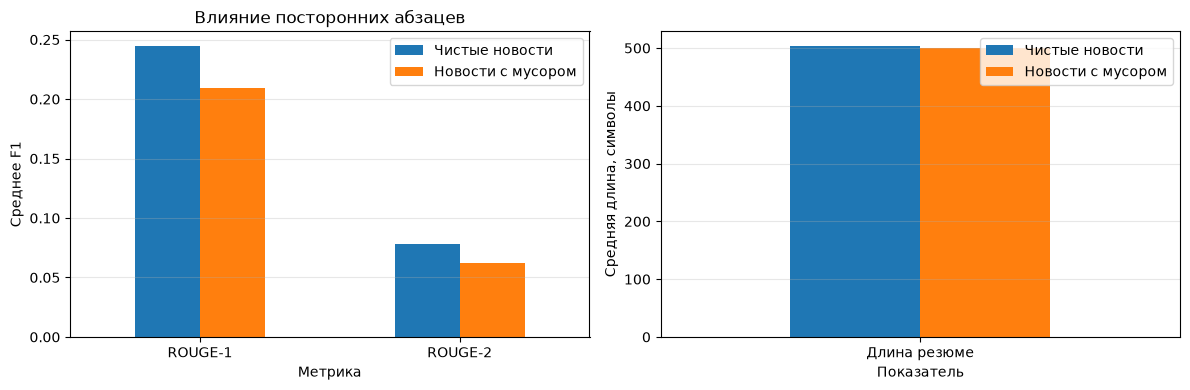

In [20]:
clean_news, noisy_news = [], []
for record in noise_test:
    item = record['inputs']
    clean_text, noisy_text = clean_and_noisy_text(item)
    common = {key: item[key] for key in ('id', 'corpus', 'title')}
    common['reference'] = record['expectations']['expected_response']
    clean_news.append({**common, 'text': clean_text})
    noisy_news.append({**common, 'text': noisy_text})

clean_results = summary_results(clean_news, prompt)
noisy_results = summary_results(noisy_news, prompt)
noise_comparison = pd.DataFrame({
    'Чистые новости': summary_metrics(clean_results),
    'Новости с мусором': summary_metrics(noisy_results),
}).T
noise_changes = noise_comparison.loc['Новости с мусором'] - noise_comparison.loc['Чистые новости']
print('Новостей в каждом варианте:', len(noise_test))
print(noise_comparison)
print('Изменение после загрязнения:')
print(noise_changes)

with mlflow.start_run(run_name='v3_clean_vs_noisy'):
    mlflow.log_params({'dataset_id': v3_dataset_id, 'summary_prompt_uri': summary_prompt_uri,
                       'n_eval': len(noise_test), 'model': MODEL_FILENAME})
    for name, values in zip(('clean', 'noisy'), noise_comparison.to_dict('records')):
        mlflow.log_metrics({f'{name}_{key}': float(value) for key, value in values.items()})
    mlflow.log_dict({'clean': clean_results, 'noisy': noisy_results}, 'predictions.json')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
noise_comparison[['rouge1_f1', 'rouge2_f1']].rename(
    columns={'rouge1_f1': 'ROUGE-1', 'rouge2_f1': 'ROUGE-2'}).T.plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Влияние посторонних абзацев', xlabel='Метрика', ylabel='Среднее F1')
noise_comparison[['mean_chars']].rename(columns={'mean_chars': 'Длина резюме'}).T.plot.bar(ax=axes[1], rot=0)
axes[1].set(xlabel='Показатель', ylabel='Средняя длина, символы')
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### Вывод по заданию 2

Сравнение проведено на одних и тех же **50 новостях Gazeta** из `noise_test`. Сортировка по ID и ограничение `EVAL_N=50` в шаблоне выбирают новости этого корпуса. В каждую добавлено по три посторонних абзаца; модель, исходный prompt и эталоны в обоих вариантах одинаковы.

После загрязнения ROUGE-1 снизился с **0,2446 до 0,2096**: на **0,0350**, или примерно **14,3%**. ROUGE-2 снизился с **0,0780 до 0,0624**: на **0,0156**, или примерно **20,0%**.

Средняя длина резюме почти не изменилась: **503,52 → 500,26 символа**, разница **−3,26 символа**. Посторонние абзацы ухудшили соответствие эталонам, хотя длина ответа осталась близкой. Поэтому по одной длине резюме такую ошибку подготовки данных обнаружить нельзя.


### Фильтрация посторонних абзацев

Посторонние абзацы искажают резюме, поэтому их полезно обнаружить до суммаризации. Это задача классификации: для каждого абзаца необходимо определить, относится ли он к новости. Решим ее той же языковой моделью, без дообучения, с помощью промпта.

Модели передаются заголовок и пронумерованные абзацы новости. Она возвращает метку `relevant` или `irrelevant` для каждого абзаца в формате JSON. Абзацы с меткой `irrelevant` удаляются, остальные передаются на суммаризацию. Определять посторонние абзацы только по заголовку и содержанию соседних абзацев непросто: вставка из новости на близкую тему может выглядеть уместной, а короткий заголовок дает мало информации.

Строгий формат ответа нужен для автоматической обработки, но маленькая модель не всегда его соблюдает. Ответ считается некорректным, если он не разбирается как JSON, число меток не совпадает с числом абзацев или встречаются недопустимые значения. В этом случае фильтр ничего не удаляет и сохраняет все абзацы: ошибочное удаление нужного текста вреднее, чем пропуск постороннего. Такие ответы учитываются отдельно как доля некорректных ответов (`invalid_json_rate`), поскольку это самостоятельный показатель надежности фильтра.

In [21]:
FILTER_PROMPT = (
    'Прочитай абзацы новости. В текст могут быть случайно вставлены посторонние абзацы из других новостей. '
    'Для каждого абзаца определи, относится ли он к заголовку. '
    'Верни только JSON: {"labels":["relevant" или "irrelevant", ...]}.')

In [22]:
def filter_messages(item, prompt=FILTER_PROMPT):
    numbered = '\n'.join(f'{i + 1}. {p["text"]}' for i, p in enumerate(item['paragraphs']))
    return [{'role': 'user', 'content': f"{prompt}\n\nЗаголовок: {item['title']}\n\nАбзацы:\n{numbered}"}]


def parse_labels(text, size):
    text = text.replace('```json', '').replace('```', '')
    try:
        labels = json.loads(text.strip())['labels']
        if not isinstance(labels, list) or len(labels) != size or any(
                x not in ('relevant', 'irrelevant') for x in labels):
            raise ValueError('Некорректные метки')
        return labels, False
    except (json.JSONDecodeError, KeyError, TypeError, ValueError):
        print(text)
        return ['relevant'] * size, True


def filter_news(item, generate=ask_llm, prompt=FILTER_PROMPT):
    answer = generate(filter_messages(item, prompt)[0]['content'])
    labels, invalid = parse_labels(answer, len(item['paragraphs']))
    kept = [p['text'] for p, label in zip(item['paragraphs'], labels) if label == 'relevant']
    return {'true': [p['label'] for p in item['paragraphs']], 'pred': labels, 'invalid': invalid,
            'cleaned': {**item, 'paragraphs': kept}}


def filter_metrics(rows):
    true = [label for row in rows for label in row['true']]
    pred = [label for row in rows for label in row['pred']]
    precision, recall, f1, _ = precision_recall_fscore_support(true, pred, average='binary', pos_label='irrelevant',
                                                               zero_division=0)
    return {'accuracy': accuracy_score(true, pred), 'precision': precision, 'recall': recall, 'f1': f1,
            'invalid_json_rate': np.mean([row['invalid'] for row in rows])}

### Оценка фильтра

Оценим фильтр на тех же загрязненных новостях из test, что и в предыдущем сравнении. Истинные метки известны: исходные абзацы имеют метку `relevant`, вставленные `irrelevant`. Сравним ответы модели с ними.

Задача решается как бинарная классификация, где положительным считается класс `irrelevant`, то есть посторонний абзац. Поэтому метрики имеют следующий смысл:

- **Precision**: какая доля абзацев, которые фильтр счел посторонними, действительно посторонние. Низкая precision означает, что фильтр удаляет полезный текст.
- **Recall**: какая доля посторонних абзацев фильтр нашел. Низкий recall означает, что мусор остается в тексте.
- **F1**: среднее гармоническое precision и recall.
- **Accuracy**: доля абзацев с правильной меткой. Метрика дает завышенную оценку, потому что исходных абзацев больше, чем вставленных.
- **`invalid_json_rate`**: доля ответов, которые не удалось разобрать.


In [23]:
assert noise_test, 'В test нет загрязненных новостей для сравнения'
test_v3 = []
for record in noise_test[:]:
    item = dict(record['inputs'])
    item['reference'] = record['expectations']['expected_response']
    test_v3.append(item)

baseline_filter = [filter_news(item) for item in tqdm(test_v3, desc='Фильтрация', mininterval=10)]
trivial = [{'true': row['true'], 'pred': ['relevant'] * len(row['true']), 'invalid': False} for row in baseline_filter]
filter_table = pd.DataFrame(
    {'все relevant': filter_metrics(trivial), 'исходный фильтр': filter_metrics(baseline_filter)}).T
filter_table.loc['все relevant', 'invalid_json_rate'] = np.nan
print(filter_table)

Фильтрация:   0%|                                       | 0/50 [00:00<?, ?it/s]

Фильтрация:   6%|█▊                             | 3/50 [00:13<03:31,  4.49s/it]

Фильтрация:   6%|█▊                             | 3/50 [00:24<03:31,  4.49s/it]

Фильтрация:  12%|███▋                           | 6/50 [00:26<03:09,  4.31s/it]

{"labels":["irrelevant","relevant","relevant","irrelevant","relevant","relevant","irrelevant","relevant","irrelevant"]}


Фильтрация:  12%|███▋                           | 6/50 [00:40<03:09,  4.31s/it]

... (25 outputs left out)

Фильтрация:  94%|████████████████████████████▏ | 47/50 [03:41<00:14,  4.98s/it]

Фильтрация:  98%|█████████████████████████████▍| 49/50 [03:52<00:05,  5.05s/it]

Фильтрация: 100%|██████████████████████████████| 50/50 [03:56<00:00,  4.73s/it]

                 accuracy  precision    recall        f1  invalid_json_rate
все relevant     0.620253   0.000000  0.000000  0.000000                NaN
исходный фильтр  0.916456   0.846154  0.953333  0.896552               0.02


Сравните precision и recall фильтра с правилом «все relevant». Высокий recall означает, что найдено много вставок, но при низкой precision вместе с ними удаляется много полезных абзацев. `invalid_json_rate` показывает отдельно, как часто фильтр не вернул корректный формат. Конкретные значения зависят от модели и текущего запуска.

**Задание 3.** Сравните качество суммаризации без фильтра и с фильтром.

1. Для загрязненных новостей из `test_v3` постройте резюме в трех вариантах: по чистому тексту, по тексту с посторонними абзацами и по тексту после фильтрации.
2. Вычислите ROUGE-1, ROUGE-2 и среднюю длину резюме для каждого варианта и сведите результаты в таблицу.
3. Для каждого из вариантов определите, какую долю удаленных абзацев составляют полезные, то есть сколько исходного текста фильтр потерял.
4. Постройте столбчатую диаграмму ROUGE-1 и ROUGE-2: по горизонтали метрики, столбцы соответствуют трем вариантам.
5. Найдите по одному примеру, когда фильтр удалил полезный абзац и когда оставил посторонний. Как это повлияло на резюме?
6. Сопоставьте качество фильтрации (precision, recall) и качество резюме. Достаточно ли высокого recall, чтобы резюме вернулось к уровню чистых новостей? Объясните, почему.

Суммаризация:   0%|                                     | 0/50 [00:00<?, ?it/s]

Суммаризация:   2%|▌                            | 1/50 [00:14<11:46, 14.42s/it]

Суммаризация:   6%|█▋                           | 3/50 [00:29<07:21,  9.39s/it]

Суммаризация:   6%|█▋                           | 3/50 [00:44<07:21,  9.39s/it]

Суммаризация:  10%|██▉                          | 5/50 [00:47<06:50,  9.13s/it]

Суммаризация:  10%|██▉                          | 5/50 [00:58<06:50,  9.13s/it]

... (37 outputs left out)

Суммаризация:  96%|██████████████████████████▉ | 48/50 [06:37<00:17,  8.56s/it]

Суммаризация: 100%|████████████████████████████| 50/50 [06:50<00:00,  7.96s/it]

Суммаризация: 100%|████████████████████████████| 50/50 [06:50<00:00,  8.22s/it]

                   rouge1_f1  rouge2_f1  mean_chars
Чистые новости      0.244618   0.078047      503.52
Новости с мусором   0.209594   0.062408      500.26
После фильтрации    0.237465   0.075981      491.50
Удаление абзацев:
                   removed_paragraphs  useful_removed  useful_among_removed  \
Чистые новости                  150.0             0.0              0.000000   
Новости с мусором                 0.0             0.0              0.000000   
После фильтрации                169.0            26.0              0.153846   

                   lost_useful_share  
Чистые новости              0.000000  
Новости с мусором           0.000000  
После фильтрации            0.106122  
useful_among_removed — доля полезных среди удалённых; lost_useful_share — доля потерянных исходных абзацев.
При отсутствии удалений доли приняты равными 0. В чистом варианте удалены только известные вставки.


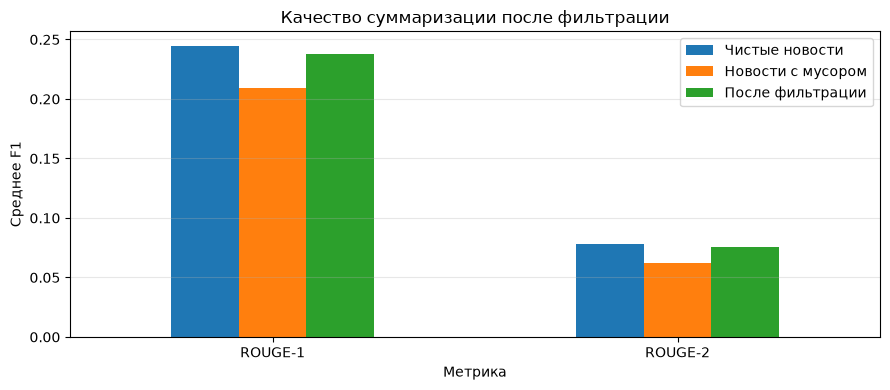


Удалён полезный абзац
ID: Gazeta:125 Заголовок: Старость и радость
Абзац: Билли Айдол для российских меломанов последние лет пять стоит первым номером в воображаемом списке стыдных удовольствий, который могли бы составить российские меломаны. Говорить о нем принято в том смысле, что, ну, да, конечно, музыка-то у него не очень, но сам-то парень о-го-го, да к тому же и красавец. Этот последний аргумент в характеристике Айдола решающий – «белокурая бестия» (или «белый мусор» – кому как больше нравится) взорвала зарождающееся MTV не музыкальным новаторством, а варварской наглостью, пергидрольной гривой и агрессивной готовностью угодить и нашим, и вашим. В общем, перед московским концертом Билли Айдола вокруг «Лужников» было почти не встретить грязных панков и прочих неформалов – сплошь приличные, часто пузатые люди, вполне соответствующие квартирующему на малой спортивной арене ГЦКЗ «Россия». Пока публика заполняла трибуны, на сцене выражала уважение к легенде группа «Радио Чача» — новый 

9339

In [24]:
filtered_results = summary_results([row['cleaned'] for row in baseline_filter], prompt)
summary_comparison = pd.concat([
    noise_comparison,
    pd.DataFrame({'После фильтрации': summary_metrics(filtered_results)}).T,
])
print(summary_comparison)

relevant_count = sum(label == 'relevant' for row in baseline_filter for label in row['true'])
irrelevant_count = sum(label == 'irrelevant' for row in baseline_filter for label in row['true'])
removed_count = sum(label == 'irrelevant' for row in baseline_filter for label in row['pred'])
useful_removed = sum(true == 'relevant' and pred == 'irrelevant'
                     for row in baseline_filter for true, pred in zip(row['true'], row['pred']))
removal_table = pd.DataFrame({
    'Чистые новости': {'removed_paragraphs': irrelevant_count, 'useful_removed': 0,
                       'useful_among_removed': 0.0, 'lost_useful_share': 0.0},
    'Новости с мусором': {'removed_paragraphs': 0, 'useful_removed': 0,
                          'useful_among_removed': 0.0, 'lost_useful_share': 0.0},
    'После фильтрации': {'removed_paragraphs': removed_count, 'useful_removed': useful_removed,
                         'useful_among_removed': useful_removed / removed_count if removed_count else 0.0,
                         'lost_useful_share': useful_removed / relevant_count if relevant_count else 0.0},
}).T
print('Удаление абзацев:')
print(removal_table)
print('useful_among_removed — доля полезных среди удалённых; lost_useful_share — доля потерянных исходных абзацев.')
print('При отсутствии удалений доли приняты равными 0. В чистом варианте удалены только известные вставки.')

fig, ax = plt.subplots(figsize=(9, 4))
summary_comparison[['rouge1_f1', 'rouge2_f1']].rename(
    columns={'rouge1_f1': 'ROUGE-1', 'rouge2_f1': 'ROUGE-2'}).T.plot.bar(ax=ax, rot=0)
ax.set(title='Качество суммаризации после фильтрации', xlabel='Метрика', ylabel='Среднее F1')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

error_examples = []
for name, true_label, predicted_label in (
    ('Удалён полезный абзац', 'relevant', 'irrelevant'),
    ('Оставлен посторонний абзац', 'irrelevant', 'relevant'),
):
    found = next(((i, j) for i, row in enumerate(baseline_filter)
                  for j, (true, pred) in enumerate(zip(row['true'], row['pred']))
                  if true == true_label and pred == predicted_label), None)
    print('\n' + name)
    if found is None:
        print('Таких ошибок в выбранных новостях нет.')
        continue
    i, j = found
    item = test_v3[i]
    print('ID:', item['id'], 'Заголовок:', item['title'])
    print('Абзац:', item['paragraphs'][j]['text'])
    print('Эталон:', item['reference'])
    example = {'error': name, 'id': item['id'], 'paragraph': item['paragraphs'][j]['text'],
               'reference': item['reference']}
    for variant, results in (('Чистый текст', clean_results), ('С мусором', noisy_results),
                             ('После фильтрации', filtered_results)):
        print(variant + ':', results[i]['summary'])
        values = summary_metrics([results[i]])
        print('ROUGE-1:', round(values['rouge1_f1'], 4), 'ROUGE-2:', round(values['rouge2_f1'], 4))
        example[variant] = {'summary': results[i]['summary'], **values}
    error_examples.append(example)

with mlflow.start_run(run_name='v3_filtered_summary'):
    mlflow.log_params({'dataset_id': v3_dataset_id, 'summary_prompt_uri': summary_prompt_uri,
                       'n_eval': len(test_v3), 'model': MODEL_FILENAME})
    mlflow.log_text(FILTER_PROMPT, 'filter_prompt.txt')
    mlflow.log_metrics({key: float(value) for key, value in summary_comparison.loc['После фильтрации'].items()})
    mlflow.log_metrics({f'filter_{key}': float(value)
                        for key, value in filter_table.loc['исходный фильтр'].items()})
    mlflow.log_metrics({'useful_among_removed': float(removal_table.loc['После фильтрации', 'useful_among_removed']),
                        'lost_useful_share': float(removal_table.loc['После фильтрации', 'lost_useful_share'])})
    mlflow.log_dict({'filtered': filtered_results}, 'predictions.json')
    mlflow.log_dict({'examples': error_examples}, 'filter_errors.json')

results = {'config': CONFIG, 'source_comparison': source_comparison.to_dict('index'),
           'prompt_comparison': prompt_comparison.to_dict('records'),
           'noise_comparison': noise_comparison.to_dict('index'),
           'noise_changes': noise_changes.to_dict(),
           'filter_metrics': filter_table.loc['исходный фильтр'].to_dict(),
           'summary_comparison': summary_comparison.to_dict('index'),
           'removal_table': removal_table.to_dict('index'), 'error_examples': error_examples}
(CACHE_DIR / 'results.json').write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding='utf-8')


### Вывод по заданию 3

Фильтрация улучшила ROUGE-1 с **0,2096 до 0,2375**, ROUGE-2 — с **0,0624 до 0,0760**. Однако чистый вариант остался лучше: **0,2446** и **0,0780** соответственно. Средняя длина резюме после фильтрации составила **491,50 символа**.

Precision фильтра равен **0,8462**, recall — **0,9533**. Найдены 143 из 150 посторонних абзацев. Из 169 удалённых абзацев **26 оказались полезными**: это **15,38% удалённых** и **10,61% исходных полезных абзацев**. В 2% ответов нарушен ожидаемый формат; для них шаблон сохраняет все абзацы.

В новости **`Gazeta:125`** фильтр удалил полезный абзац о концерте Билли Айдола. Резюме загрязнённого текста ушло в тему безработицы в Белоруссии, а после фильтрации — в тему дела Владимира Белашева. Нужная тема концерта не восстановилась: ROUGE-1 после фильтрации равен 0,1159 против 0,1414 по чистому тексту.

В новости **`Gazeta:12`** о переходе Google с Windows на другие системы остался посторонний абзац о Надежде Толоконниковой. Сведения из этого абзаца не попали в резюме, а ответы до и после фильтрации совпали. Следовательно, пропущенная вставка не всегда меняет конечный ответ.

Высокого recall недостаточно для возврата к качеству чистых новостей. Фильтр должен одновременно находить вставки и сохранять полезный текст. В этом запуске высокая полнота сопровождалась потерей части исходных абзацев, а средние ROUGE остались ниже чистого варианта.
